In [1]:

%pip install datasets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
!python -V

Python 3.11.5


In [2]:
from datasets import load_dataset

ds = load_dataset("MMJagannath/SLM-Movie-Recommendation")

print(ds)


DatasetDict({
    train: Dataset({
        features: ['messages'],
        num_rows: 23988
    })
    validation: Dataset({
        features: ['messages'],
        num_rows: 2999
    })
    test: Dataset({
        features: ['messages'],
        num_rows: 2999
    })
})


In [5]:
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from transformers import AutoTokenizer

# Load Qwen3 tokenizer
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")

# Convert conversations into token IDs
def process(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )

    ids = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    return {"ids": ids, "len": len(ids)}

# Tokenize Netflix dataset
tokenized = ds.map(
    process,
    remove_columns=["messages"],
    load_from_cache_file=False,
    desc="Tokenizing Netflix dataset"
)

# Create a separate output folder
output_dir = Path.cwd() / "netflix_tokens"
output_dir.mkdir(parents=True, exist_ok=True)

# Save each split
for split in ["train", "validation", "test"]:

    filename = output_dir / f"{split}.bin"
    total_tokens = 0

    with filename.open("wb") as f:
        for example in tqdm(
            tokenized[split],
            desc=f"Writing {split}"
        ):
            ids = np.asarray(
                example["ids"],
                dtype=np.uint32
            )

            ids.tofile(f)
            total_tokens += len(ids)

    print(f"{split}.bin saved: {total_tokens} tokens")

print("CELL-4 COMPLETED SUCCESSFULLY!")

Tokenizing Netflix dataset:   0%|          | 0/23988 [00:00<?, ? examples/s]

Tokenizing Netflix dataset:   0%|          | 0/2999 [00:00<?, ? examples/s]

Tokenizing Netflix dataset:   0%|          | 0/2999 [00:00<?, ? examples/s]

Writing train:   0%|          | 0/23988 [00:00<?, ?it/s]

train.bin saved: 2166249 tokens


Writing validation:   0%|          | 0/2999 [00:00<?, ?it/s]

validation.bin saved: 269695 tokens


Writing test:   0%|          | 0/2999 [00:00<?, ?it/s]

test.bin saved: 272891 tokens
CELL-4 COMPLETED SUCCESSFULLY!


In [6]:
%pip install -q torch

import torch
import numpy as np
from pathlib import Path

# Batch settings
batch_size = 8
block_size = 128
device = "cuda" if torch.cuda.is_available() else "cpu"

# Folder containing our tokenized Netflix dataset
token_dir = Path.cwd() / "netflix_tokens"

def get_batch(split):
    filename = token_dir / f"{split}.bin"

    data = np.memmap(
        filename,
        dtype=np.uint32,
        mode="r"
    )

    ix = torch.randint(
        len(data) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        torch.from_numpy(
            np.array(data[i:i + block_size], dtype=np.int64)
        )
        for i in ix.tolist()
    ])

    y = torch.stack([
        torch.from_numpy(
            np.array(data[i + 1:i + 1 + block_size], dtype=np.int64)
        )
        for i in ix.tolist()
    ])

    x = x.to(device)
    y = y.to(device)

    return x, y

# Test the batch loading function
x, y = get_batch("train")

print("Device:", device)
print("Input batch shape:", x.shape)
print("Target batch shape:", y.shape)
print("CELL-5 COMPLETED SUCCESSFULLY!")

Note: you may need to restart the kernel to use updated packages.
Device: cpu
Input batch shape: torch.Size([8, 128])
Target batch shape: torch.Size([8, 128])
CELL-5 COMPLETED SUCCESSFULLY!



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import torch

def compute_rope_params(
    head_dim,
    theta_base=10000,
    context_length=4096,
    dtype=torch.float32
):
    assert head_dim % 2 == 0, "Head dimension must be even"

    inv_freq = 1.0 / (
        theta_base ** (
            torch.arange(0, head_dim, 2, dtype=dtype) / head_dim
        )
    )

    positions = torch.arange(context_length, dtype=dtype)

    angles = positions[:, None] * inv_freq[None, :]
    angles = torch.cat([angles, angles], dim=1)

    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin


def apply_rope(x, cos, sin):
    batch_size, num_heads, seq_len, head_dim = x.shape

    assert head_dim % 2 == 0, "Head dimension must be even"

    x1 = x[..., :head_dim // 2]
    x2 = x[..., head_dim // 2:]

    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)

    rotated = torch.cat((-x2, x1), dim=-1)

    x_rotated = (x * cos) + (rotated * sin)

    return x_rotated.to(dtype=x.dtype)


# Test positional encoding
cos, sin = compute_rope_params(head_dim=64)

sample = torch.randn(2, 4, 128, 64)

result = apply_rope(sample, cos, sin)

print("Original shape:", sample.shape)
print("RoPE output shape:", result.shape)
print("CELL-6 COMPLETED SUCCESSFULLY!")

Original shape: torch.Size([2, 4, 128, 64])
RoPE output shape: torch.Size([2, 4, 128, 64])
CELL-6 COMPLETED SUCCESSFULLY!


In [4]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer

# Use the same tokenizer as CELL-4
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")

# RMS Normalization
class RMSNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        x_float = x.float()
        x_norm = x_float * torch.rsqrt(
            x_float.pow(2).mean(dim=-1, keepdim=True) + 1e-6
        )
        return (x_norm * self.weight).to(x.dtype)


# Grouped Query Attention
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_groups):
        super().__init__()
        assert d_model % n_heads == 0
        assert n_heads % n_kv_groups == 0

        self.n_heads = n_heads
        self.n_kv_groups = n_kv_groups
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(
            d_model, n_kv_groups * self.head_dim, bias=False
        )
        self.v_proj = nn.Linear(
            d_model, n_kv_groups * self.head_dim, bias=False
        )
        self.o_proj = nn.Linear(d_model, d_model, bias=False)

        self.q_norm = RMSNorm(self.head_dim)
        self.k_norm = RMSNorm(self.head_dim)

    def forward(self, x, cos, sin):
        b, t, _ = x.shape

        q = self.q_proj(x).view(
            b, t, self.n_heads, self.head_dim
        ).transpose(1, 2)

        k = self.k_proj(x).view(
            b, t, self.n_kv_groups, self.head_dim
        ).transpose(1, 2)

        v = self.v_proj(x).view(
            b, t, self.n_kv_groups, self.head_dim
        ).transpose(1, 2)

        q = apply_rope(self.q_norm(q), cos, sin)
        k = apply_rope(self.k_norm(k), cos, sin)

        repeat = self.n_heads // self.n_kv_groups
        k = k.repeat_interleave(repeat, dim=1)
        v = v.repeat_interleave(repeat, dim=1)

        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True
        )

        y = y.transpose(1, 2).contiguous().view(b, t, -1)
        return self.o_proj(y)


# SwiGLU Feed Forward
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)

    def forward(self, x):
        return self.down(
            F.silu(self.gate(x)) * self.up(x)
        )


# Transformer Block
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_groups, d_ff):
        super().__init__()

        self.norm1 = RMSNorm(d_model)
        self.attn = GroupedQueryAttention(
            d_model, n_heads, n_kv_groups
        )
        self.norm2 = RMSNorm(d_model)
        self.ffn = SwiGLUFeedForward(d_model, d_ff)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.norm1(x), cos, sin)
        x = x + self.ffn(self.norm2(x))
        return x


# Complete Small Language Model
class Qwen3Model(nn.Module):
    def __init__(
        self, vocab_size, d_model, n_heads,
        n_kv_groups, n_layers, d_ff, max_seq_len
    ):
        super().__init__()

        self.tok_emb = nn.Embedding(vocab_size, d_model)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model, n_heads, n_kv_groups, d_ff
            )
            for _ in range(n_layers)
        ])

        self.final_norm = RMSNorm(d_model)
        self.out_head = nn.Linear(
            d_model, vocab_size, bias=False
        )

        # Share embedding and output weights
        self.out_head.weight = self.tok_emb.weight
        nn.init.normal_(self.tok_emb.weight, std=0.02)

        cos, sin = compute_rope_params(
            head_dim=d_model // n_heads,
            context_length=max_seq_len
        )

        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

        self.max_seq_len = max_seq_len

    def forward(self, input_ids, targets=None):
        assert input_ids.shape[1] <= self.max_seq_len

        x = self.tok_emb(input_ids)

        for block in self.blocks:
            x = block(x, self.cos, self.sin)

        logits = self.out_head(self.final_norm(x))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


# Configuration: target 10-20 million parameters
QWEN3_CONFIG = {
    "vocab_size": len(tokenizer),
    "d_model": 96,
    "n_heads": 3,
    "n_kv_groups": 1,
    "n_layers": 6,
    "d_ff": 256,
    "max_seq_len": 128
}

torch.manual_seed(123)
model = Qwen3Model(**QWEN3_CONFIG)

total_params = sum(p.numel() for p in model.parameters())

print("Total model parameters:", f"{total_params:,}")
print("Parameters in millions:", round(total_params / 1e6, 2))

# Small forward-pass test
sample = torch.randint(
    0, len(tokenizer), (1, 8)
)

with torch.no_grad():
    logits, loss = model(sample, sample)

print("Output shape:", logits.shape)
print("CELL-7 COMPLETED SUCCESSFULLY!")


Total model parameters: 15,151,680
Parameters in millions: 15.15
Output shape: torch.Size([1, 8, 151669])
CELL-7 COMPLETED SUCCESSFULLY!


In [5]:

import torch
from pathlib import Path
from torch.optim.lr_scheduler import (
    LinearLR, CosineAnnealingLR, SequentialLR
)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# Training configuration
learning_rate = 1e-4
min_lr = 1e-5
max_iters = 30
warmup_steps = 5
eval_interval = 10
eval_batches = 3

# Small batches for CPU training
batch_size = 1
block_size = 64
gradient_accumulation_steps = 4
grad_clip = 1.0

# Locate the token files created in CELL-4
cwd = Path.cwd()

possible_dirs = [
    cwd / "netflix_tokens",
    cwd / ".ipynb_checkpoints" / "netflix_tokens",
    cwd.parent / "netflix_tokens",
    cwd.parent / ".ipynb_checkpoints" / "netflix_tokens"
]

token_dir = next(
    (
        p for p in possible_dirs
        if all(
            (p / f"{split}.bin").exists()
            for split in ["train", "validation", "test"]
        )
    ),
    None
)

if token_dir is None:
    raise FileNotFoundError(
        "Netflix token files not found. Check CELL-4 output folder."
    )

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-8
)

# Learning rate warmup
scheduler_warmup = LinearLR(
    optimizer,
    start_factor=0.1,
    end_factor=1.0,
    total_iters=warmup_steps
)

# Cosine learning rate decay
scheduler_decay = CosineAnnealingLR(
    optimizer,
    T_max=max_iters - warmup_steps,
    eta_min=min_lr
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[scheduler_warmup, scheduler_decay],
    milestones=[warmup_steps]
)

print("Device:", device)
print("Model parameters:", f"{total_params:,}")
print("Learning rate:", learning_rate)
print("Training iterations:", max_iters)
print("Batch size:", batch_size)
print("Block size:", block_size)
print("Token directory:", token_dir)
print("Optimizer: AdamW")
print("Scheduler: Warmup + Cosine Decay")
print("CELL-8 COMPLETED SUCCESSFULLY!")


Device: cpu
Model parameters: 15,151,680
Learning rate: 0.0001
Training iterations: 30
Batch size: 1
Block size: 64
Token directory: c:\Users\jagan\SLM-Movie-Recommendation\.ipynb_checkpoints\netflix_tokens
Optimizer: AdamW
Scheduler: Warmup + Cosine Decay
CELL-8 COMPLETED SUCCESSFULLY!


In [6]:

import numpy as np
import torch

# Load batches from our Netflix token files
def get_batch(split):
    file_path = token_dir / f"{split}.bin"

    data = np.memmap(
        file_path,
        dtype=np.uint32,
        mode="r"
    )

    ix = torch.randint(
        0,
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        torch.tensor(
            data[i:i + block_size].astype(np.int64),
            dtype=torch.long
        )
        for i in ix.tolist()
    ])

    y = torch.stack([
        torch.tensor(
            data[i + 1:i + block_size + 1].astype(np.int64),
            dtype=torch.long
        )
        for i in ix.tolist()
    ])

    return x.to(device), y.to(device)


# Test training batch
X, Y = get_batch("train")

print("Training input shape:", X.shape)
print("Training target shape:", Y.shape)

# Test validation batch
X_val, Y_val = get_batch("validation")

print("Validation input shape:", X_val.shape)
print("Validation target shape:", Y_val.shape)

# Test initial model loss
model.eval()

with torch.no_grad():
    logits, loss = model(X, Y)

print("Initial training loss:", round(loss.item(), 4))

model.train()

print("CELL-9 COMPLETED SUCCESSFULLY!")


Training input shape: torch.Size([1, 64])
Training target shape: torch.Size([1, 64])
Validation input shape: torch.Size([1, 64])
Validation target shape: torch.Size([1, 64])
Initial training loss: 11.8889
CELL-9 COMPLETED SUCCESSFULLY!


In [7]:

import time
import torch

model.train()
optimizer.zero_grad(set_to_none=True)

start_time = time.perf_counter()

# Get a training batch
X, Y = get_batch("train")

# Forward pass
logits, loss = model(X, Y)

print("Loss before update:", round(loss.item(), 4))

# Backpropagation
loss.backward()

# Prevent excessively large gradients
torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=grad_clip
)

# Update model parameters
optimizer.step()
scheduler.step()
optimizer.zero_grad(set_to_none=True)

elapsed = time.perf_counter() - start_time

print("Optimizer step: COMPLETED")
print("Current learning rate:",
      optimizer.param_groups[0]["lr"])
print("Training step time:",
      round(elapsed, 2), "seconds")

print("CELL-10 COMPLETED SUCCESSFULLY!")


Loss before update: 11.9304
Optimizer step: COMPLETED
Current learning rate: 2.8e-05
Training step time: 0.36 seconds
CELL-10 COMPLETED SUCCESSFULLY!


In [8]:

import time
import torch
from pathlib import Path

model.train()
training_start = time.perf_counter()

# Step 1 was already completed in CELL-10
for step in range(2, max_iters + 1):

    optimizer.zero_grad(set_to_none=True)
    running_loss = 0.0

    # Gradient accumulation
    for _ in range(gradient_accumulation_steps):
        X, Y = get_batch("train")

        logits, loss = model(X, Y)
        running_loss += loss.item()

        (loss / gradient_accumulation_steps).backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=grad_clip
    )

    optimizer.step()
    scheduler.step()

    # Evaluate every 10 steps
    if step % eval_interval == 0 or step == max_iters:
        model.eval()
        val_losses = []

        with torch.no_grad():
            for _ in range(eval_batches):
                X_val, Y_val = get_batch("validation")
                _, val_loss = model(X_val, Y_val)
                val_losses.append(val_loss.item())

        model.train()

        print(
            f"Step {step}/{max_iters} | "
            f"Train Loss: {running_loss / gradient_accumulation_steps:.4f} | "
            f"Validation Loss: {sum(val_losses) / len(val_losses):.4f}"
        )

# Save the test checkpoint
project_dir = (
    token_dir.parent.parent
    if token_dir.parent.name == ".ipynb_checkpoints"
    else token_dir.parent
)

checkpoint_dir = project_dir / "models"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "netflix_slm_smoketest.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "config": QWEN3_CONFIG,
    "steps_completed": max_iters
}, checkpoint_path)

elapsed = time.perf_counter() - training_start

print("Training time:", round(elapsed, 2), "seconds")
print("Checkpoint saved:", checkpoint_path)
print("CELL-11 COMPLETED SUCCESSFULLY!")


Step 10/30 | Train Loss: 11.8919 | Validation Loss: 11.8665
Step 20/30 | Train Loss: 11.7859 | Validation Loss: 11.8595
Step 30/30 | Train Loss: 11.7833 | Validation Loss: 11.7073
Training time: 14.24 seconds
Checkpoint saved: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_smoketest.pt
CELL-11 COMPLETED SUCCESSFULLY!


In [9]:

import time
import torch
from pathlib import Path

# Continue training the existing model
model = model.to(device)
model.train()

# New schedule for extended training
extended_steps = 500
extended_lr = 2e-4
extended_warmup = 20

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=extended_lr,
    betas=(0.9, 0.95),
    weight_decay=0.1
)

from torch.optim.lr_scheduler import (
    LinearLR, CosineAnnealingLR, SequentialLR
)

warmup = LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=extended_warmup
)

decay = CosineAnnealingLR(
    optimizer,
    T_max=extended_steps - extended_warmup,
    eta_min=1e-5
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup, decay],
    milestones=[extended_warmup]
)

save_dir = project_dir / "models"
save_dir.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
start_time = time.perf_counter()

print("Extended training started...")

for step in range(1, extended_steps + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_loss = 0.0

    for _ in range(gradient_accumulation_steps):
        X, Y = get_batch("train")
        _, loss = model(X, Y)

        train_loss += loss.item()
        (loss / gradient_accumulation_steps).backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=grad_clip
    )

    optimizer.step()
    scheduler.step()

    if step % 100 == 0:
        model.eval()
        val_losses = []

        with torch.no_grad():
            for _ in range(5):
                X_val, Y_val = get_batch("validation")
                _, val_loss = model(X_val, Y_val)
                val_losses.append(val_loss.item())

        avg_val = sum(val_losses) / len(val_losses)
        avg_train = train_loss / gradient_accumulation_steps

        print(
            f"Step {step}/{extended_steps} | "
            f"Train Loss: {avg_train:.4f} | "
            f"Val Loss: {avg_val:.4f}",
            flush=True
        )

        checkpoint = {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "config": QWEN3_CONFIG,
            "step": step,
            "validation_loss": avg_val
        }

        torch.save(
            checkpoint,
            save_dir / "netflix_slm_training_latest.pt"
        )

        if avg_val < best_val_loss:
            best_val_loss = avg_val
            torch.save(
                checkpoint,
                save_dir / "netflix_slm_training_best.pt"
            )

        model.train()

elapsed = time.perf_counter() - start_time

print("Training time:", round(elapsed, 2), "seconds")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoints saved in:", save_dir)
print("CELL-12 COMPLETED SUCCESSFULLY!")


Extended training started...
Step 100/500 | Train Loss: 9.0722 | Val Loss: 9.1170
Step 200/500 | Train Loss: 6.7742 | Val Loss: 6.7750
Step 300/500 | Train Loss: 6.0378 | Val Loss: 5.9035
Step 400/500 | Train Loss: 5.8680 | Val Loss: 6.1889
Step 500/500 | Train Loss: 5.6974 | Val Loss: 5.9557
Training time: 239.44 seconds
Best validation loss: 5.9035
Checkpoints saved in: c:\Users\jagan\SLM-Movie-Recommendation\models
CELL-12 COMPLETED SUCCESSFULLY!


In [10]:

import torch

best_path = save_dir / "netflix_slm_training_best.pt"
latest_path = save_dir / "netflix_slm_training_latest.pt"

# Prepare the same validation batches for both models
validation_batches = [
    get_batch("validation")
    for _ in range(20)
]

results = {}

for name, path in [
    ("Best checkpoint", best_path),
    ("Latest checkpoint", latest_path)
]:
    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()
    losses = []

    with torch.no_grad():
        for X_val, Y_val in validation_batches:
            _, loss = model(X_val, Y_val)
            losses.append(loss.item())

    average_loss = sum(losses) / len(losses)
    results[name] = (average_loss, path)

    print(
        f"{name} | "
        f"Step: {checkpoint['step']} | "
        f"Validation Loss: {average_loss:.4f}"
    )

# Select the better checkpoint
selected_name = min(
    results,
    key=lambda name: results[name][0]
)

selected_loss, selected_path = results[selected_name]

selected_checkpoint = torch.load(
    selected_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    selected_checkpoint["model_state_dict"]
)

model.train()

print("Selected checkpoint:", selected_name)
print("Selected validation loss:", round(selected_loss, 4))
print("CELL-13 COMPLETED SUCCESSFULLY!")


Best checkpoint | Step: 300 | Validation Loss: 6.0114
Latest checkpoint | Step: 500 | Validation Loss: 5.6786
Selected checkpoint: Latest checkpoint
Selected validation loss: 5.6786
CELL-13 COMPLETED SUCCESSFULLY!


In [11]:

import torch

model.eval()

prompt = "Recommend a Netflix comedy movie and explain why."

messages = [
    {"role": "user", "content": prompt}
]

# Format the prompt using our tokenizer
input_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

input_ids = tokenizer.encode(
    input_text,
    add_special_tokens=False,
    return_tensors="pt"
).to(device)

generated = input_ids.clone()

# Generate up to 60 new tokens
with torch.no_grad():
    for _ in range(60):
        context = generated[:, -block_size:]

        logits, _ = model(context)

        next_logits = logits[:, -1, :] / 0.8

        # Sample from the top 40 candidates
        top_values, top_indices = torch.topk(
            next_logits, k=40
        )

        probabilities = torch.softmax(
            top_values, dim=-1
        )

        sampled = torch.multinomial(
            probabilities, num_samples=1
        )

        next_token = top_indices.gather(1, sampled)

        generated = torch.cat(
            [generated, next_token], dim=1
        )

        if next_token.item() in [
            tokenizer.eos_token_id,
            tokenizer.convert_tokens_to_ids("<|im_end|>")
        ]:
            break

# Decode only the generated response
response_ids = generated[0, input_ids.shape[1]:]

response = tokenizer.decode(
    response_ids,
    skip_special_tokens=True
)

print("USER PROMPT:")
print(prompt)

print("\nSLM RESPONSE:")
print(response)

print("\nCELL-14 COMPLETED SUCCESSFULLY!")


USER PROMPT:
Recommend a Netflix comedy movie and explain why.

SLM RESPONSE:
assistant
 are<think>Yousystem assistant

CELL-14 COMPLETED SUCCESSFULLY!


In [12]:

from datasets import load_dataset

ds = load_dataset("MMJagannath/SLM-Movie-Recommendation")

print("=== TRAINING EXAMPLES ===")

for i in range(3):
    print(f"\nEXAMPLE {i + 1}")

    messages = ds["train"][i]["messages"]

    for message in messages:
        print(
            message["role"].upper() + ":",
            str(message["content"])[:500]
        )

    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    token_count = len(
        tokenizer.encode(
            formatted,
            add_special_tokens=False
        )
    )

    print("Tokens in example:", token_count)

print("\n=== MODEL STATISTICS ===")

embedding_params = model.tok_emb.weight.numel()
total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", total_params)
print("Embedding parameters:", embedding_params)
print(
    "Embedding percentage:",
    round(embedding_params / total_params * 100, 2),
    "%"
)
print("Training context length:", block_size)

print("\nCELL-15 COMPLETED SUCCESSFULLY!")


=== TRAINING EXAMPLES ===

EXAMPLE 1
SYSTEM: You answer questions about Netflix movies and TV shows concisely and factually.
USER: Quick facts on “Seabiscuit”: rating and release year.
ASSISTANT: "Seabiscuit" is rated PG-13 and was released in 2003.
Tokens in example: 71

EXAMPLE 2
SYSTEM: You answer questions about Netflix movies and TV shows concisely and factually.
USER: Who made Oppenheimer? Who directed it?
ASSISTANT: I don't have any record of "Oppenheimer". I only know the titles in my dataset, and I won't invent facts about this one.
Tokens in example: 76

EXAMPLE 3
SYSTEM: You are a helpful assistant providing details on movies and TV shows.
USER: "Rhyme & Reason" came out in 1997, correct?
ASSISTANT: Yes, 'Rhyme & Reason' was released in 1997.
Tokens in example: 66

=== MODEL STATISTICS ===
Total parameters: 15151680
Embedding parameters: 14560224
Embedding percentage: 96.1 %
Training context length: 64

CELL-15 COMPLETED SUCCESSFULLY!


In [13]:

from tokenizers import Tokenizer, models, trainers
from tokenizers import pre_tokenizers, decoders
from transformers import PreTrainedTokenizerFast

special_tokens = [
    "<|pad|>",
    "<|unk|>",
    "<|bos|>",
    "<|eos|>",
    "<|system|>",
    "<|user|>",
    "<|assistant|>",
    "<|end|>"
]

# Format our Netflix conversations
def format_netflix_example(example):
    parts = []

    for message in example["messages"]:
        role = message["role"]
        content = message["content"] or ""

        ending = (
            "<|eos|>"
            if role == "assistant"
            else "<|end|>"
        )

        parts.append(
            f"<|{role}|>\n{content}{ending}\n"
        )

    return "".join(parts)

# Train tokenizer only on training data
def training_texts():
    for example in ds["train"]:
        yield format_netflix_example(example)

bpe = Tokenizer(
    models.BPE(unk_token="<|unk|>")
)

bpe.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)

bpe.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=8192,
    min_frequency=2,
    special_tokens=special_tokens,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

print("Training Netflix tokenizer...")

bpe.train_from_iterator(
    training_texts(),
    trainer=trainer,
    length=len(ds["train"])
)

netflix_tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=bpe,
    unk_token="<|unk|>",
    pad_token="<|pad|>",
    bos_token="<|bos|>",
    eos_token="<|eos|>",
    additional_special_tokens=[
        "<|system|>",
        "<|user|>",
        "<|assistant|>",
        "<|end|>"
    ]
)

# Chat format for future recommendations
netflix_tokenizer.chat_template = (
    "{% for message in messages %}"
    "<|{{ message['role'] }}|>\n"
    "{{ message['content'] }}"
    "{% if message['role'] == 'assistant' %}"
    "<|eos|>"
    "{% else %}<|end|>{% endif %}\n"
    "{% endfor %}"
    "{% if add_generation_prompt %}"
    "<|assistant|>\n"
    "{% endif %}"
)

# Save the new tokenizer
tokenizer_dir = project_dir / "netflix_tokenizer_8k"

netflix_tokenizer.save_pretrained(
    str(tokenizer_dir)
)

sample_text = format_netflix_example(
    ds["train"][0]
)

sample_ids = netflix_tokenizer.encode(
    sample_text,
    add_special_tokens=False
)

print("Tokenizer vocabulary:", len(netflix_tokenizer))
print("Sample token count:", len(sample_ids))
print("Tokenizer saved:", tokenizer_dir)
print("CELL-16 COMPLETED SUCCESSFULLY!")


Training Netflix tokenizer...
Tokenizer vocabulary: 8192
Sample token count: 50
Tokenizer saved: c:\Users\jagan\SLM-Movie-Recommendation\netflix_tokenizer_8k
CELL-16 COMPLETED SUCCESSFULLY!


In [14]:

import numpy as np
from pathlib import Path

# Create a separate directory for new tokenized data
new_token_dir = project_dir / "netflix_tokens_8k"
new_token_dir.mkdir(parents=True, exist_ok=True)

print("Starting Netflix dataset retokenization...\n")

for split in ["train", "validation", "test"]:

    output_path = new_token_dir / f"{split}.bin"

    total_tokens = 0
    example_lengths = []

    with open(output_path, "wb") as f:

        for example in ds[split]:

            # Convert conversation to text
            text = format_netflix_example(example)

            # Tokenize using our new 8K tokenizer
            token_ids = netflix_tokenizer.encode(
                text,
                add_special_tokens=False
            )

            # Save tokens in binary format
            tokens = np.asarray(
                token_ids,
                dtype=np.uint32
            )

            tokens.tofile(f)

            total_tokens += len(tokens)
            example_lengths.append(len(tokens))

    print(f"{split.upper()} DATA:")
    print("Examples:", len(ds[split]))
    print("Total tokens:", total_tokens)
    print(
        "Average tokens per example:",
        round(np.mean(example_lengths), 2)
    )
    print(
        "95th percentile length:",
        round(np.percentile(example_lengths, 95))
    )
    print(
        "Longest example:",
        max(example_lengths)
    )
    print("Saved:", output_path)
    print("-" * 45)

print("\nCELL-17 COMPLETED SUCCESSFULLY!")


Starting Netflix dataset retokenization...

TRAIN DATA:
Examples: 23988
Total tokens: 1806889
Average tokens per example: 75.32
95th percentile length: 125
Longest example: 197
Saved: c:\Users\jagan\SLM-Movie-Recommendation\netflix_tokens_8k\train.bin
---------------------------------------------
VALIDATION DATA:
Examples: 2999
Total tokens: 224654
Average tokens per example: 74.91
95th percentile length: 125
Longest example: 174
Saved: c:\Users\jagan\SLM-Movie-Recommendation\netflix_tokens_8k\validation.bin
---------------------------------------------
TEST DATA:
Examples: 2999
Total tokens: 228004
Average tokens per example: 76.03
95th percentile length: 125
Longest example: 185
Saved: c:\Users\jagan\SLM-Movie-Recommendation\netflix_tokens_8k\test.bin
---------------------------------------------

CELL-17 COMPLETED SUCCESSFULLY!


In [15]:

import torch

# Improved Netflix SLM configuration
QWEN3_CONFIG_V2 = {
    "vocab_size": len(netflix_tokenizer),
    "d_model": 384,
    "n_heads": 6,
    "n_kv_groups": 2,
    "n_layers": 7,
    "d_ff": 1024,
    "max_seq_len": 128
}

torch.manual_seed(123)

# Create new model without modifying old checkpoints
model_v2 = Qwen3Model(**QWEN3_CONFIG_V2).to(device)

total_params_v2 = sum(
    p.numel() for p in model_v2.parameters()
)

embedding_params_v2 = model_v2.tok_emb.weight.numel()

print("=== IMPROVED NETFLIX SLM ===")
print("Vocabulary size:", len(netflix_tokenizer))
print("Total parameters:", total_params_v2)
print(
    "Parameters in millions:",
    round(total_params_v2 / 1_000_000, 2)
)
print(
    "Embedding percentage:",
    round(
        embedding_params_v2 / total_params_v2 * 100,
        2
    ),
    "%"
)

# Check parameter requirement
assert 10_000_000 <= total_params_v2 <= 20_000_000, (
    "Model must have 10-20 million parameters"
)

# Test forward pass
model_v2.eval()

sample_input = torch.randint(
    0,
    len(netflix_tokenizer),
    (1, 16),
    device=device
)

with torch.no_grad():
    logits, _ = model_v2(sample_input)

print("Output shape:", logits.shape)

del logits

model_v2.train()

print("Device:", device)
print("Architecture test: PASSED")
print("CELL-18 COMPLETED SUCCESSFULLY!")


=== IMPROVED NETFLIX SLM ===
Vocabulary size: 8192
Total parameters: 14162432
Parameters in millions: 14.16
Embedding percentage: 22.21 %
Output shape: torch.Size([1, 16, 8192])
Device: cpu
Architecture test: PASSED
CELL-18 COMPLETED SUCCESSFULLY!


In [16]:

import numpy as np
import torch

# New training settings
block_size_v2 = 128
batch_size_v2 = 2
gradient_accumulation_steps_v2 = 4

# Load tokens from the NEW 8K tokenizer files
def get_batch_v2(split):
    file_path = new_token_dir / f"{split}.bin"

    data = np.memmap(
        file_path,
        dtype=np.uint32,
        mode="r"
    )

    indices = torch.randint(
        0,
        len(data) - block_size_v2 - 1,
        (batch_size_v2,)
    )

    x = torch.stack([
        torch.tensor(
            data[i:i + block_size_v2].astype(np.int64),
            dtype=torch.long
        )
        for i in indices.tolist()
    ])

    y = torch.stack([
        torch.tensor(
            data[i + 1:i + block_size_v2 + 1].astype(np.int64),
            dtype=torch.long
        )
        for i in indices.tolist()
    ])

    return x.to(device), y.to(device)


# Test training batch
X, Y = get_batch_v2("train")

print("Training input shape:", X.shape)
print("Training target shape:", Y.shape)

# Test validation batch
X_val, Y_val = get_batch_v2("validation")

print("Validation input shape:", X_val.shape)
print("Validation target shape:", Y_val.shape)

# Test model forward pass and loss
model_v2.eval()

with torch.no_grad():
    logits, loss = model_v2(X, Y)

print("Initial model loss:", round(loss.item(), 4))

model_v2.train()

print("CELL-19 COMPLETED SUCCESSFULLY!")


Training input shape: torch.Size([2, 128])
Training target shape: torch.Size([2, 128])
Validation input shape: torch.Size([2, 128])
Validation target shape: torch.Size([2, 128])
Initial model loss: 9.1929
CELL-19 COMPLETED SUCCESSFULLY!


In [17]:

import torch
from torch.optim.lr_scheduler import (
    LinearLR,
    CosineAnnealingLR,
    SequentialLR
)

# Improved SLM training configuration
learning_rate_v2 = 3e-4
min_lr_v2 = 2e-5

max_iters_v2 = 1000
warmup_steps_v2 = 50

eval_interval_v2 = 100
eval_batches_v2 = 5

grad_clip_v2 = 1.0

# AdamW optimizer
optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=learning_rate_v2,
    betas=(0.9, 0.95),
    weight_decay=0.1,
    eps=1e-8
)

# Linear learning-rate warmup
scheduler_warmup_v2 = LinearLR(
    optimizer_v2,
    start_factor=0.1,
    end_factor=1.0,
    total_iters=warmup_steps_v2
)

# Cosine learning-rate decay
scheduler_decay_v2 = CosineAnnealingLR(
    optimizer_v2,
    T_max=max_iters_v2 - warmup_steps_v2,
    eta_min=min_lr_v2
)

# Combine both schedulers
scheduler_v2 = SequentialLR(
    optimizer_v2,
    schedulers=[
        scheduler_warmup_v2,
        scheduler_decay_v2
    ],
    milestones=[warmup_steps_v2]
)

print("=== NETFLIX SLM V2 TRAINING SETUP ===")
print("Device:", device)
print("Model parameters:", sum(
    p.numel() for p in model_v2.parameters()
))
print("Learning rate:", learning_rate_v2)
print("Maximum iterations:", max_iters_v2)
print("Warmup steps:", warmup_steps_v2)
print("Batch size:", batch_size_v2)
print("Block size:", block_size_v2)
print(
    "Gradient accumulation:",
    gradient_accumulation_steps_v2
)
print("Optimizer: AdamW")
print("Scheduler: Linear Warmup + Cosine Decay")
print("CELL-20 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM V2 TRAINING SETUP ===
Device: cpu
Model parameters: 14162432
Learning rate: 0.0003
Maximum iterations: 1000
Warmup steps: 50
Batch size: 2
Block size: 128
Gradient accumulation: 4
Optimizer: AdamW
Scheduler: Linear Warmup + Cosine Decay
CELL-20 COMPLETED SUCCESSFULLY!


In [18]:

import time
import torch

model_v2.train()

# First 100 steps of the planned 1000
start_step = 1
end_step = 100

# Use fixed validation batches for fair comparisons
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(2026)
    fixed_val_batches_v2 = [
        get_batch_v2("validation")
        for _ in range(eval_batches_v2)
    ]

training_start = time.perf_counter()

print("NETFLIX SLM V2 TRAINING STARTED...")
print("Device:", device)
print("Training steps:", start_step, "to", end_step)

for step in range(start_step, end_step + 1):

    model_v2.train()
    optimizer_v2.zero_grad(set_to_none=True)

    running_loss = 0.0

    for _ in range(gradient_accumulation_steps_v2):

        X, Y = get_batch_v2("train")

        logits, loss = model_v2(X, Y)

        running_loss += loss.item()

        (loss / gradient_accumulation_steps_v2).backward()

    torch.nn.utils.clip_grad_norm_(
        model_v2.parameters(),
        max_norm=grad_clip_v2
    )

    optimizer_v2.step()
    scheduler_v2.step()

    if step % 25 == 0:
        print(
            f"Step {step}/{max_iters_v2} | "
            f"Train Loss: "
            f"{running_loss / gradient_accumulation_steps_v2:.4f}",
            flush=True
        )

# Evaluate after 100 steps
model_v2.eval()
val_losses = []

with torch.no_grad():
    for X_val, Y_val in fixed_val_batches_v2:
        _, val_loss = model_v2(X_val, Y_val)
        val_losses.append(val_loss.item())

avg_val_loss = sum(val_losses) / len(val_losses)

print("Validation Loss:", round(avg_val_loss, 4))

# Save model and optimizer for continued training
checkpoint_v2 = {
    "model_state_dict": model_v2.state_dict(),
    "optimizer_state_dict": optimizer_v2.state_dict(),
    "scheduler_state_dict": scheduler_v2.state_dict(),
    "config": QWEN3_CONFIG_V2,
    "step": end_step,
    "best_val_loss": avg_val_loss
}

checkpoint_path_v2 = (
    project_dir / "models" / "netflix_slm_v2_latest.pt"
)

checkpoint_path_v2.parent.mkdir(
    parents=True, exist_ok=True
)

torch.save(checkpoint_v2, checkpoint_path_v2)

elapsed = time.perf_counter() - training_start

print("Training time:", round(elapsed, 2), "seconds")
print("Checkpoint saved:", checkpoint_path_v2)
print("Completed steps:", end_step, "/", max_iters_v2)

model_v2.train()

print("CELL-21 COMPLETED SUCCESSFULLY!")


NETFLIX SLM V2 TRAINING STARTED...
Device: cpu
Training steps: 1 to 100
Step 25/1000 | Train Loss: 7.4904
Step 50/1000 | Train Loss: 5.5027
Step 75/1000 | Train Loss: 3.8101
Step 100/1000 | Train Loss: 3.4227
Validation Loss: 3.32
Training time: 73.74 seconds
Checkpoint saved: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_latest.pt
Completed steps: 100 / 1000
CELL-21 COMPLETED SUCCESSFULLY!


In [19]:

import time
import torch

# Continue training without resetting the model
if "current_step_v2" not in globals():
    current_step_v2 = 100

if "best_val_loss_v2" not in globals():
    best_val_loss_v2 = float(checkpoint_v2["best_val_loss"])

best_checkpoint_path_v2 = (
    project_dir / "models" / "netflix_slm_v2_best.pt"
)

# Preserve the step-100 checkpoint as our first best model
if not best_checkpoint_path_v2.exists():
    torch.save(checkpoint_v2, best_checkpoint_path_v2)

print("=== CONTINUING NETFLIX SLM V2 TRAINING ===")
print("Starting after step:", current_step_v2)
print("Target step: 300")
print("Best validation loss:", round(best_val_loss_v2, 4))

start_time = time.perf_counter()

for step in range(current_step_v2 + 1, 301):

    model_v2.train()
    optimizer_v2.zero_grad(set_to_none=True)

    running_loss = 0.0

    for _ in range(gradient_accumulation_steps_v2):
        X, Y = get_batch_v2("train")

        logits, loss = model_v2(X, Y)

        running_loss += loss.item()

        (loss / gradient_accumulation_steps_v2).backward()

    torch.nn.utils.clip_grad_norm_(
        model_v2.parameters(),
        max_norm=grad_clip_v2
    )

    optimizer_v2.step()
    scheduler_v2.step()

    current_step_v2 = step

    if step % 25 == 0:
        print(
            f"Step {step}/{max_iters_v2} | "
            f"Train Loss: "
            f"{running_loss / gradient_accumulation_steps_v2:.4f}",
            flush=True
        )

    # Evaluate and save every 50 steps
    if step % 50 == 0:

        model_v2.eval()
        val_losses = []

        with torch.no_grad():
            for X_val, Y_val in fixed_val_batches_v2:
                _, val_loss = model_v2(X_val, Y_val)
                val_losses.append(val_loss.item())

        avg_val_loss = sum(val_losses) / len(val_losses)

        print(
            f"Validation Loss at step {step}: "
            f"{avg_val_loss:.4f}",
            flush=True
        )

        checkpoint_v2 = {
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer_v2.state_dict(),
            "scheduler_state_dict": scheduler_v2.state_dict(),
            "config": QWEN3_CONFIG_V2,
            "step": step,
            "best_val_loss": min(
                best_val_loss_v2, avg_val_loss
            )
        }

        # Always save latest checkpoint
        torch.save(
            checkpoint_v2,
            checkpoint_path_v2
        )

        # Save best checkpoint when validation improves
        if avg_val_loss < best_val_loss_v2:
            best_val_loss_v2 = avg_val_loss

            torch.save(
                checkpoint_v2,
                best_checkpoint_path_v2
            )

            print("New best model saved!")

elapsed = time.perf_counter() - start_time

print("\n=== TRAINING SUMMARY ===")
print("Completed steps:", current_step_v2)
print("Best validation loss:", round(best_val_loss_v2, 4))
print("Training time:", round(elapsed, 2), "seconds")
print("Latest checkpoint:", checkpoint_path_v2)
print("Best checkpoint:", best_checkpoint_path_v2)

model_v2.train()

print("CELL-22 COMPLETED SUCCESSFULLY!")


=== CONTINUING NETFLIX SLM V2 TRAINING ===
Starting after step: 100
Target step: 300
Best validation loss: 3.32
Step 125/1000 | Train Loss: 2.6717
Step 150/1000 | Train Loss: 2.6469
Validation Loss at step 150: 2.7501
New best model saved!
Step 175/1000 | Train Loss: 2.3365
Step 200/1000 | Train Loss: 1.8175
Validation Loss at step 200: 2.4523
New best model saved!
Step 225/1000 | Train Loss: 2.1725
Step 250/1000 | Train Loss: 1.8477
Validation Loss at step 250: 2.3187
New best model saved!
Step 275/1000 | Train Loss: 1.9054
Step 300/1000 | Train Loss: 2.0935
Validation Loss at step 300: 2.1930
New best model saved!

=== TRAINING SUMMARY ===
Completed steps: 300
Best validation loss: 2.193
Training time: 132.51 seconds
Latest checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_latest.pt
Best checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_best.pt
CELL-22 COMPLETED SUCCESSFULLY!


In [20]:

import time
import torch

# Continue from the completed training state
assert current_step_v2 == 300, (
    f"Expected step 300, found {current_step_v2}"
)

target_step_v2 = 500

print("=== NETFLIX SLM V2 TRAINING CONTINUED ===")
print("Starting from step:", current_step_v2 + 1)
print("Target step:", target_step_v2)
print("Previous best validation loss:", best_val_loss_v2)

start_time = time.perf_counter()

for step in range(current_step_v2 + 1, target_step_v2 + 1):

    model_v2.train()
    optimizer_v2.zero_grad(set_to_none=True)

    running_loss = 0.0

    for _ in range(gradient_accumulation_steps_v2):

        X, Y = get_batch_v2("train")

        logits, loss = model_v2(X, Y)

        running_loss += loss.item()

        (loss / gradient_accumulation_steps_v2).backward()

    torch.nn.utils.clip_grad_norm_(
        model_v2.parameters(),
        max_norm=grad_clip_v2
    )

    optimizer_v2.step()
    scheduler_v2.step()

    current_step_v2 = step

    if step % 25 == 0:
        print(
            f"Step {step}/{max_iters_v2} | "
            f"Train Loss: "
            f"{running_loss / gradient_accumulation_steps_v2:.4f}",
            flush=True
        )

    if step % 50 == 0:

        model_v2.eval()
        val_losses = []

        with torch.no_grad():
            for X_val, Y_val in fixed_val_batches_v2:
                _, val_loss = model_v2(X_val, Y_val)
                val_losses.append(val_loss.item())

        avg_val_loss = sum(val_losses) / len(val_losses)

        print(
            f"Validation Loss at step {step}: "
            f"{avg_val_loss:.4f}",
            flush=True
        )

        is_best = avg_val_loss < best_val_loss_v2

        if is_best:
            best_val_loss_v2 = avg_val_loss

        checkpoint_v2 = {
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer_v2.state_dict(),
            "scheduler_state_dict": scheduler_v2.state_dict(),
            "config": QWEN3_CONFIG_V2,
            "step": step,
            "best_val_loss": best_val_loss_v2
        }

        torch.save(
            checkpoint_v2,
            checkpoint_path_v2
        )

        if is_best:
            torch.save(
                checkpoint_v2,
                best_checkpoint_path_v2
            )
            print("New best model saved!")

elapsed = time.perf_counter() - start_time

print("\n=== TRAINING SUMMARY ===")
print("Completed steps:", current_step_v2)
print("Best validation loss:", round(best_val_loss_v2, 4))
print("Training time:", round(elapsed, 2), "seconds")
print("Latest checkpoint:", checkpoint_path_v2)
print("Best checkpoint:", best_checkpoint_path_v2)

model_v2.train()

print("CELL-23 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM V2 TRAINING CONTINUED ===
Starting from step: 301
Target step: 500
Previous best validation loss: 2.192998194694519
Step 325/1000 | Train Loss: 1.6266
Step 350/1000 | Train Loss: 1.9028
Validation Loss at step 350: 2.1084
New best model saved!
Step 375/1000 | Train Loss: 2.0006
Step 400/1000 | Train Loss: 1.5465
Validation Loss at step 400: 2.0273
New best model saved!
Step 425/1000 | Train Loss: 1.4424
Step 450/1000 | Train Loss: 1.7903
Validation Loss at step 450: 1.9734
New best model saved!
Step 475/1000 | Train Loss: 1.5450
Step 500/1000 | Train Loss: 1.9712
Validation Loss at step 500: 1.9282
New best model saved!

=== TRAINING SUMMARY ===
Completed steps: 500
Best validation loss: 1.9282
Training time: 131.57 seconds
Latest checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_latest.pt
Best checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_best.pt
CELL-23 COMPLETED SUCCESSFULLY!


In [21]:

import torch

model_v2.eval()

@torch.no_grad()
def generate_netflix_response_v2(messages, max_new_tokens=80):

    # Use the same formatting used during training
    prompt_messages = [
        m for m in messages
        if m["role"] != "assistant"
    ]

    prompt_text = format_netflix_example({
        "messages": prompt_messages
    }) + "<|assistant|>\n"

    input_ids = netflix_tokenizer.encode(
        prompt_text,
        add_special_tokens=False
    )

    context_size = QWEN3_CONFIG_V2["max_seq_len"]

    input_ids = input_ids[-context_size:]

    tokens = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device
    )

    eos_id = netflix_tokenizer.convert_tokens_to_ids(
        "<|eos|>"
    )

    generated_ids = []

    for _ in range(max_new_tokens):

        context = tokens[:, -context_size:]

        logits, _ = model_v2(context)

        # Greedy decoding for reproducible testing
        next_id = torch.argmax(
            logits[:, -1, :],
            dim=-1,
            keepdim=True
        )

        token_id = next_id.item()

        if token_id == eos_id:
            break

        generated_ids.append(token_id)

        tokens = torch.cat(
            [tokens, next_id],
            dim=1
        )

    return netflix_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()


print("=== NETFLIX SLM V2 GENERATION TEST ===")

# Evaluate on two unseen test examples
for i in range(2):

    example = ds["test"][i]
    messages = example["messages"]

    question = next(
        m["content"]
        for m in messages
        if m["role"] == "user"
    )

    expected = next(
        m["content"]
        for m in messages
        if m["role"] == "assistant"
    )

    prediction = generate_netflix_response_v2(messages)

    print(f"\n--- TEST EXAMPLE {i + 1} ---")
    print("QUESTION:", question)
    print("EXPECTED:", expected)
    print("MODEL RESPONSE:", prediction)


# Test a new recommendation request
print("\n--- RECOMMENDATION TEST ---")

custom_messages = [
    {
        "role": "user",
        "content": (
            "Recommend a Netflix comedy movie "
            "and explain why."
        )
    }
]

recommendation = generate_netflix_response_v2(
    custom_messages
)

print("QUESTION:", custom_messages[0]["content"])
print("MODEL RESPONSE:", recommendation)

model_v2.train()

print("\nCELL-24 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM V2 GENERATION TEST ===

--- TEST EXAMPLE 1 ---
QUESTION: What's the gap between the release year and the Netflix date added for “Miniforce: Super Dino Power”?
EXPECTED: 'Miniforce: Super Dino Power' was released in 2020 and added to Netflix in 2021, a gap of 1 year.
MODEL RESPONSE: "The Last Girls" was added to Netflix on July 1, 2021, is a TV Show, and was added to Netflix on July 1, 2021.

--- TEST EXAMPLE 2 ---
QUESTION: Was 'Osuofia in London' released in 2008?
EXPECTED: No, 'Osuofia in London' was released in 2003, not 2008.
MODEL RESPONSE: Yes, "The Last Girls" was released in 2021.

--- RECOMMENDATION TEST ---
QUESTION: Recommend a Netflix comedy movie and explain why.
MODEL RESPONSE: "The Last Patlu: The Movie" is a TV Show. It came out in 2021. It has 1 Season. It is rated TV-MA (intended for mature audiences). It was produced in United States. It features S. It features S. It features S. It features S. It features S. It features S, S, S, and S. It was added to

In [22]:

import time
import torch

# Continue from the existing 500-step model
assert current_step_v2 == 500, (
    f"Expected step 500, found {current_step_v2}"
)

target_step_v2 = 1000
training_history_v2 = []

print("=== FINAL NETFLIX SLM V2 TRAINING ===")
print("Starting step:", current_step_v2 + 1)
print("Target step:", target_step_v2)
print("Previous best validation loss:", best_val_loss_v2)

start_time = time.perf_counter()

for step in range(current_step_v2 + 1, target_step_v2 + 1):

    model_v2.train()
    optimizer_v2.zero_grad(set_to_none=True)

    running_loss = 0.0

    for _ in range(gradient_accumulation_steps_v2):

        X, Y = get_batch_v2("train")

        logits, loss = model_v2(X, Y)

        running_loss += loss.item()

        (loss / gradient_accumulation_steps_v2).backward()

    torch.nn.utils.clip_grad_norm_(
        model_v2.parameters(),
        max_norm=grad_clip_v2
    )

    optimizer_v2.step()
    scheduler_v2.step()

    current_step_v2 = step

    # Evaluate and save every 100 steps
    if step % 100 == 0:

        train_loss = (
            running_loss / gradient_accumulation_steps_v2
        )

        model_v2.eval()
        val_losses = []

        with torch.no_grad():
            for X_val, Y_val in fixed_val_batches_v2:
                _, val_loss = model_v2(X_val, Y_val)
                val_losses.append(val_loss.item())

        avg_val_loss = sum(val_losses) / len(val_losses)

        training_history_v2.append({
            "step": step,
            "train_loss": train_loss,
            "val_loss": avg_val_loss
        })

        is_best = avg_val_loss < best_val_loss_v2

        if is_best:
            best_val_loss_v2 = avg_val_loss

        checkpoint_v2 = {
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer_v2.state_dict(),
            "scheduler_state_dict": scheduler_v2.state_dict(),
            "config": QWEN3_CONFIG_V2,
            "step": step,
            "best_val_loss": best_val_loss_v2,
            "history": training_history_v2
        }

        torch.save(
            checkpoint_v2,
            checkpoint_path_v2
        )

        if is_best:
            torch.save(
                checkpoint_v2,
                best_checkpoint_path_v2
            )

        print(
            f"Step {step}/{target_step_v2} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Best: {best_val_loss_v2:.4f}",
            flush=True
        )

elapsed = time.perf_counter() - start_time

model_v2.train()

print("\n=== FINAL TRAINING SUMMARY ===")
print("Completed steps:", current_step_v2)
print("Best validation loss:", round(best_val_loss_v2, 4))
print("Training time:", round(elapsed, 2), "seconds")
print("Latest checkpoint:", checkpoint_path_v2)
print("Best checkpoint:", best_checkpoint_path_v2)
print("CELL-25 COMPLETED SUCCESSFULLY!")


=== FINAL NETFLIX SLM V2 TRAINING ===
Starting step: 501
Target step: 1000
Previous best validation loss: 1.9282257556915283
Step 600/1000 | Train Loss: 1.9046 | Val Loss: 1.8724 | Best: 1.8724
Step 700/1000 | Train Loss: 1.8827 | Val Loss: 1.8348 | Best: 1.8348
Step 800/1000 | Train Loss: 1.2947 | Val Loss: 1.8012 | Best: 1.8012
Step 900/1000 | Train Loss: 1.1474 | Val Loss: 1.7612 | Best: 1.7612
Step 1000/1000 | Train Loss: 1.4958 | Val Loss: 1.7522 | Best: 1.7522

=== FINAL TRAINING SUMMARY ===
Completed steps: 1000
Best validation loss: 1.7522
Training time: 441.33 seconds
Latest checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_latest.pt
Best checkpoint: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_best.pt
CELL-25 COMPLETED SUCCESSFULLY!


In [23]:

import matplotlib.pyplot as plt

print("=== NETFLIX SLM V2 LOSS VISUALIZATION ===")

steps = [item["step"] for item in training_history_v2]
train_losses = [
    item["train_loss"] for item in training_history_v2
]
val_losses = [
    item["val_loss"] for item in training_history_v2
]

plt.figure(figsize=(10, 5))

plt.plot(
    steps, train_losses,
    marker="o", label="Training Loss"
)

plt.plot(
    steps, val_losses,
    marker="s", label="Validation Loss"
)

plt.title("Netflix SLM V2 - Training Progress")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

graph_path = (
    project_dir / "models" / "netflix_slm_v2_loss_curve.png"
)

plt.savefig(graph_path, dpi=150)
plt.show()

print("Graph saved at:", graph_path)
print("Best validation loss:", round(best_val_loss_v2, 4))
print("CELL-26 COMPLETED SUCCESSFULLY!")


ModuleNotFoundError: No module named 'matplotlib'

In [24]:

%pip install matplotlib


   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------- ----------------- 5.2/9.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 29.0 MB/s  0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 30.2 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


=== NETFLIX SLM V2 LOSS VISUALIZATION ===


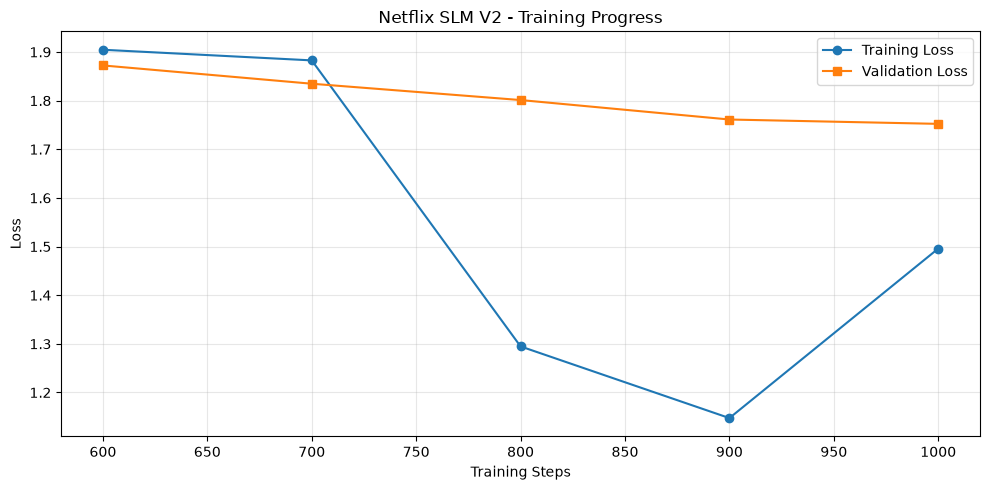

Graph saved at: c:\Users\jagan\SLM-Movie-Recommendation\models\netflix_slm_v2_loss_curve.png
Best validation loss: 1.7522
CELL-26 COMPLETED SUCCESSFULLY!


In [25]:

import matplotlib.pyplot as plt

print("=== NETFLIX SLM V2 LOSS VISUALIZATION ===")

steps = [item["step"] for item in training_history_v2]
train_losses = [
    item["train_loss"] for item in training_history_v2
]
val_losses = [
    item["val_loss"] for item in training_history_v2
]

plt.figure(figsize=(10, 5))

plt.plot(
    steps, train_losses,
    marker="o", label="Training Loss"
)

plt.plot(
    steps, val_losses,
    marker="s", label="Validation Loss"
)

plt.title("Netflix SLM V2 - Training Progress")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

graph_path = (
    project_dir / "models" / "netflix_slm_v2_loss_curve.png"
)

plt.savefig(graph_path, dpi=150)
plt.show()

print("Graph saved at:", graph_path)
print("Best validation loss:", round(best_val_loss_v2, 4))
print("CELL-26 COMPLETED SUCCESSFULLY!")


In [26]:

import torch

print("=== NETFLIX SLM V2 FINAL MODEL TEST ===")

# Load the best saved checkpoint
best_checkpoint = torch.load(
    best_checkpoint_path_v2,
    map_location=device,
    weights_only=True
)

model_v2.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model_v2.eval()

print("Checkpoint loaded successfully!")
print("Training step:", best_checkpoint["step"])
print(
    "Best validation loss:",
    round(best_checkpoint["best_val_loss"], 4)
)

# Test on unseen Netflix dataset examples
for i in range(2):

    example = ds["test"][i]
    messages = example["messages"]

    question = next(
        m["content"] for m in messages
        if m["role"] == "user"
    )

    expected = next(
        m["content"] for m in messages
        if m["role"] == "assistant"
    )

    prediction = generate_netflix_response_v2(
        messages,
        max_new_tokens=80
    )

    print(f"\n--- TEST EXAMPLE {i+1} ---")
    print("QUESTION:", question)
    print("EXPECTED:", expected)
    print("MODEL RESPONSE:", prediction)

# Test a recommendation prompt
print("\n--- NETFLIX RECOMMENDATION TEST ---")

prompt = [
    {
        "role": "user",
        "content": (
            "Recommend a Netflix comedy movie "
            "and explain why."
        )
    }
]

response = generate_netflix_response_v2(
    prompt,
    max_new_tokens=80
)

print("QUESTION:", prompt[0]["content"])
print("MODEL RESPONSE:", response)

print("\nCELL-27 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM V2 FINAL MODEL TEST ===
Checkpoint loaded successfully!
Training step: 1000
Best validation loss: 1.7522

--- TEST EXAMPLE 1 ---
QUESTION: What's the gap between the release year and the Netflix date added for “Miniforce: Super Dino Power”?
EXPECTED: 'Miniforce: Super Dino Power' was released in 2020 and added to Netflix in 2021, a gap of 1 year.
MODEL RESPONSE: 'The Last Stray' was released in 2021 and added to Netflix in 2021, a gap of 1 year.

--- TEST EXAMPLE 2 ---
QUESTION: Was 'Osuofia in London' released in 2008?
EXPECTED: No, 'Osuofia in London' was released in 2003, not 2008.
MODEL RESPONSE: Yes, 'The Last Stray' was released in 2021.

--- NETFLIX RECOMMENDATION TEST ---
QUESTION: Recommend a Netflix comedy movie and explain why.
MODEL RESPONSE: 'The Last Boy de título' is a Movie. It was released in 2021. It runs 97 minutes. It is rated TV-MA. It was produced in United States. It was directed by David L. It features T. It features T. It was added to Netflix on

In [27]:

import json
import torch
from pathlib import Path

print("=== NETFLIX SLM V2 HUGGING FACE PREPARATION ===")

# Create folder for Hugging Face model files
hf_model_dir = project_dir / "huggingface_netflix_slm_v2"
hf_model_dir.mkdir(parents=True, exist_ok=True)

# Save best trained model weights
model_weights = {
    key: value.detach().cpu()
    for key, value in best_checkpoint["model_state_dict"].items()
}

torch.save(
    model_weights,
    hf_model_dir / "pytorch_model.bin"
)

print("Model weights saved!")

# Save our Netflix-specific tokenizer
netflix_tokenizer.save_pretrained(hf_model_dir)

print("Tokenizer saved!")

# Save model architecture configuration
model_config = {
    "model_type": "netflix_qwen3_inspired",
    "architectures": ["Qwen3Model"],
    **QWEN3_CONFIG_V2,
    "training_steps": 1000,
    "best_validation_loss": float(best_val_loss_v2),
    "dataset": "MMJagannath/SLM-Movie-Recommendation"
}

with open(
    hf_model_dir / "config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_config, f, indent=4)

print("Model configuration saved!")

# Create a simple model card
readme = """---
language: en
license: mit
tags:
- text-generation
- netflix
- movies
- qwen3-inspired
- student-project
---

# Netflix SLM V2

A small language model trained from scratch on a
Netflix movie and TV show conversational dataset.

## Architecture
Qwen3-inspired Transformer with:
- Grouped Query Attention
- Rotary Position Embeddings
- RMSNorm
- SwiGLU feed-forward layers

## Training
- Dataset: MMJagannath/SLM-Movie-Recommendation
- Training steps: 1000
- Best validation loss: 1.7522
- Training device: CPU

## Limitations
This is an experimental student project.
Generated Netflix facts and recommendations may
be incorrect. Outputs should be verified.

## Loading
The weights use a custom Qwen3-inspired architecture.
The matching model implementation is required to
load and run the weights.
"""

(hf_model_dir / "README.md").write_text(
    readme,
    encoding="utf-8"
)

print("Model README saved!")

print("\n=== PREPARED FILES ===")

for file in sorted(hf_model_dir.iterdir()):
    print(file.name)

print("\nFolder location:", hf_model_dir)
print("\nCELL-28 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM V2 HUGGING FACE PREPARATION ===
Model weights saved!
Tokenizer saved!
Model configuration saved!
Model README saved!

=== PREPARED FILES ===
chat_template.jinja
config.json
pytorch_model.bin
README.md
tokenizer.json
tokenizer_config.json

Folder location: c:\Users\jagan\SLM-Movie-Recommendation\huggingface_netflix_slm_v2

CELL-28 COMPLETED SUCCESSFULLY!


In [28]:

import ast
import importlib.util
import torch

print("=== EXPORTING NETFLIX SLM ARCHITECTURE ===")

required_definitions = [
    "compute_rope_params",
    "apply_rope",
    "RMSNorm",
    "GroupedQueryAttention",
    "SwiGLUFeedForward",
    "TransformerBlock",
    "Qwen3Model"
]

# Retrieve model definitions from executed notebook cells
history = get_ipython().history_manager.input_hist_raw
found = {}

for cell_source in history:
    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
            if node.name in required_definitions:
                found[node.name] = (
                    ast.get_source_segment(cell_source, node)
                    or ast.unparse(node)
                )

missing = [
    name for name in required_definitions
    if name not in found
]

if missing:
    raise RuntimeError(
        "Missing architecture definitions: "
        + ", ".join(missing)
    )

# Assemble standalone Python architecture file
header = """from __future__ import annotations
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
"""

source_code = header + "\n\n"

for name in required_definitions:
    source_code += found[name] + "\n\n"

architecture_path = (
    hf_model_dir / "modeling_netflix_slm.py"
)

architecture_path.write_text(
    source_code,
    encoding="utf-8"
)

print("Architecture file created!")
print("Location:", architecture_path)

# Verify the exported architecture can be imported
spec = importlib.util.spec_from_file_location(
    "modeling_netflix_slm",
    architecture_path
)

exported_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exported_module)

# Verify compatibility with saved model weights
verification_model = exported_module.Qwen3Model(
    **QWEN3_CONFIG_V2
)

saved_weights = torch.load(
    hf_model_dir / "pytorch_model.bin",
    map_location="cpu",
    weights_only=True
)

verification_model.load_state_dict(
    saved_weights,
    strict=True
)

print("Architecture imported successfully!")
print("Saved weights loaded successfully!")
print(
    "Model parameters:",
    sum(p.numel() for p in verification_model.parameters())
)

del verification_model

print("\nCELL-29 COMPLETED SUCCESSFULLY!")


=== EXPORTING NETFLIX SLM ARCHITECTURE ===
Architecture file created!
Location: c:\Users\jagan\SLM-Movie-Recommendation\huggingface_netflix_slm_v2\modeling_netflix_slm.py
Architecture imported successfully!
Saved weights loaded successfully!
Model parameters: 14162432

CELL-29 COMPLETED SUCCESSFULLY!


In [29]:

import textwrap
import subprocess
import sys

print("=== CREATING NETFLIX SLM INFERENCE SCRIPT ===")

inference_code = r'''
import argparse
import json
from pathlib import Path

import torch
from transformers import AutoTokenizer
from modeling_netflix_slm import Qwen3Model

MODEL_DIR = Path(__file__).resolve().parent

with open(MODEL_DIR / "config.json", encoding="utf-8") as f:
    config = json.load(f)

architecture_keys = [
    "vocab_size",
    "d_model",
    "n_heads",
    "n_kv_groups",
    "n_layers",
    "d_ff",
    "max_seq_len"
]

model_config = {
    key: config[key] for key in architecture_keys
}

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_DIR,
    use_fast=True
)

model = Qwen3Model(**model_config)

weights = torch.load(
    MODEL_DIR / "pytorch_model.bin",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(weights, strict=True)
model.eval()


@torch.inference_mode()
def generate_response(prompt, max_new_tokens=80):

    prompt_text = (
        f"<|user|>\n{prompt}<|end|>\n"
        "<|assistant|>\n"
    )

    input_ids = tokenizer.encode(
        prompt_text,
        add_special_tokens=False
    )

    context_length = config["max_seq_len"]

    tokens = torch.tensor(
        [input_ids[-context_length:]],
        dtype=torch.long
    )

    eos_id = tokenizer.convert_tokens_to_ids(
        "<|eos|>"
    )

    generated = []

    for _ in range(max_new_tokens):

        context = tokens[:, -context_length:]

        logits, _ = model(context)

        next_id = torch.argmax(
            logits[:, -1, :],
            dim=-1
        ).item()

        if next_id == eos_id:
            break

        generated.append(next_id)

        next_token = torch.tensor(
            [[next_id]],
            dtype=torch.long
        )

        tokens = torch.cat(
            [tokens, next_token],
            dim=1
        )

    return tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()


if __name__ == "__main__":

    parser = argparse.ArgumentParser()
    parser.add_argument(
        "prompt",
        nargs="?",
        default="Recommend a Netflix comedy movie."
    )
    args = parser.parse_args()

    print("Question:", args.prompt)
    print(
        "Model response:",
        generate_response(args.prompt)
    )
'''

inference_path = hf_model_dir / "inference.py"

inference_path.write_text(
    textwrap.dedent(inference_code).lstrip(),
    encoding="utf-8"
)

# Record the dependencies
(hf_model_dir / "requirements.txt").write_text(
    "torch\ntransformers\n",
    encoding="utf-8"
)

print("Inference script created:", inference_path)

# Test it as a separate Python program
result = subprocess.run(
    [
        sys.executable,
        str(inference_path),
        "Recommend a Netflix comedy movie."
    ],
    capture_output=True,
    text=True,
    timeout=120
)

print("\n=== STANDALONE INFERENCE TEST ===")
print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Inference script test failed.")

print("CELL-30 COMPLETED SUCCESSFULLY!")


=== CREATING NETFLIX SLM INFERENCE SCRIPT ===
Inference script created: c:\Users\jagan\SLM-Movie-Recommendation\huggingface_netflix_slm_v2\inference.py

=== STANDALONE INFERENCE TEST ===
Question: Recommend a Netflix comedy movie.
Model response: 'The Last Boy' is a Movie.

CELL-30 COMPLETED SUCCESSFULLY!


In [30]:

%pip install huggingface_hub ipywidgets

from huggingface_hub import HfApi, login

print("=== HUGGING FACE ACCOUNT CONNECTION ===")

api = HfApi()

try:
    account = api.whoami()
    print("Already logged in!")
except Exception:
    print("Please log in to Hugging Face.")
    login()
    account = api.whoami()

print("Connected account:", account["name"])
print("CELL-31 COMPLETED SUCCESSFULLY!")



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
=== HUGGING FACE ACCOUNT CONNECTION ===
Please log in to Hugging Face.


Connected account: MMJagannath
CELL-31 COMPLETED SUCCESSFULLY!


In [31]:

from huggingface_hub import HfApi

print("=== UPLOADING NETFLIX SLM V2 ===")

api = HfApi()

repo_id = "MMJagannath/Netflix-SLM-V2"

# Create a public Hugging Face model repository
api.create_repo(
    repo_id=repo_id,
    repo_type="model",
    private=False,
    exist_ok=True
)

print("Model repository created or found!")

# Upload trained model and supporting files
commit_info = api.upload_folder(
    folder_path=str(hf_model_dir),
    repo_id=repo_id,
    repo_type="model",
    commit_message="Upload trained Netflix SLM V2"
)

print("Model files uploaded successfully!")

# Verify repository exists
repo_info = api.model_info(repo_id)

print("\n=== HUGGING FACE MODEL DETAILS ===")
print("Repository:", repo_info.id)
print("Model URL:", f"https://huggingface.co/{repo_id}")
print("Uploaded files:")

for file in repo_info.siblings:
    print("-", file.rfilename)

print("\nCELL-32 COMPLETED SUCCESSFULLY!")


=== UPLOADING NETFLIX SLM V2 ===
Model repository created or found!
Model files uploaded successfully!

=== HUGGING FACE MODEL DETAILS ===
Repository: MMJagannath/Netflix-SLM-V2
Model URL: https://huggingface.co/MMJagannath/Netflix-SLM-V2
Uploaded files:
- .gitattributes
- README.md
- __pycache__/modeling_netflix_slm.cpython-311.pyc
- chat_template.jinja
- config.json
- inference.py
- modeling_netflix_slm.py
- pytorch_model.bin
- requirements.txt
- tokenizer.json
- tokenizer_config.json

CELL-32 COMPLETED SUCCESSFULLY!


In [32]:

from huggingface_hub import HfApi
import shutil

print("=== FINAL HUGGING FACE VERIFICATION ===")

api = HfApi()

# Find unnecessary generated Python cache files
files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="model"
)

cache_files = [
    file for file in files
    if "__pycache__/" in file or file.endswith(".pyc")
]

# Remove cache files from Hugging Face
for file in cache_files:
    api.delete_file(
        path_in_repo=file,
        repo_id=repo_id,
        repo_type="model",
        commit_message="Remove unnecessary Python cache"
    )
    print("Removed:", file)

# Remove local cache from the upload folder
local_cache = hf_model_dir / "__pycache__"

if local_cache.exists():
    shutil.rmtree(local_cache)

# Verify final repository
info = api.model_info(repo_id)

print("\n=== FINAL UPLOADED FILES ===")

for file in info.siblings:
    print("-", file.rfilename)

print("\nModel URL:")
print(f"https://huggingface.co/{repo_id}")

print("\nCELL-33 COMPLETED SUCCESSFULLY!")


=== FINAL HUGGING FACE VERIFICATION ===
Removed: __pycache__/modeling_netflix_slm.cpython-311.pyc

=== FINAL UPLOADED FILES ===
- .gitattributes
- README.md
- chat_template.jinja
- config.json
- inference.py
- modeling_netflix_slm.py
- pytorch_model.bin
- requirements.txt
- tokenizer.json
- tokenizer_config.json

Model URL:
https://huggingface.co/MMJagannath/Netflix-SLM-V2

CELL-33 COMPLETED SUCCESSFULLY!


In [33]:

from pathlib import Path
import subprocess
import shutil

print("=== NETFLIX SLM GITHUB PROJECT CHECK ===")

print("\nProject folder:", project_dir)

print("\n=== JUPYTER NOTEBOOKS ===")
notebooks = list(project_dir.glob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        print("-", notebook.name)
else:
    print("No notebook found in project root.")

print("\n=== MODEL FILES ===")
for filename in [
    "modeling_netflix_slm.py",
    "inference.py",
    "config.json",
    "requirements.txt",
    "README.md",
    "pytorch_model.bin"
]:
    path = hf_model_dir / filename
    print(filename, ":", "FOUND" if path.exists() else "MISSING")

print("\n=== GIT STATUS ===")

if not (project_dir / ".git").exists():
    print("Git repository not initialized locally.")
elif shutil.which("git") is None:
    print("Git command not available.")
else:
    for command in [
        ["git", "remote", "-v"],
        ["git", "status", "--short"],
        ["git", "branch", "--show-current"]
    ]:
        result = subprocess.run(
            command,
            cwd=project_dir,
            capture_output=True,
            text=True
        )
        print("\n$", " ".join(command))
        print(result.stdout.strip() or result.stderr.strip() or "(none)")

print("\nCELL-34 COMPLETED SUCCESSFULLY!")


=== NETFLIX SLM GITHUB PROJECT CHECK ===

Project folder: c:\Users\jagan\SLM-Movie-Recommendation

=== JUPYTER NOTEBOOKS ===
- data_preprocessing.ipynb
- Untitled.ipynb
- Untitled1.ipynb
- Untitled2.ipynb

=== MODEL FILES ===
modeling_netflix_slm.py : FOUND
inference.py : FOUND
config.json : FOUND
requirements.txt : FOUND
README.md : FOUND
pytorch_model.bin : FOUND

=== GIT STATUS ===
Git repository not initialized locally.

CELL-34 COMPLETED SUCCESSFULLY!
